# HW3 Part 2 — LightGBM Experiments

Baseline from `05_lightgbm.ipynb`: **0.90480 CV / 0.90477 OOF**. Target for top 60: AUC ≥ 0.92.

Three experiments push toward that target:
1. **`feature_fraction` sweep** — the well-known Santander trick of forcing each tree to use very few features (`feature_fraction=0.05`), combined with shallow trees (`num_leaves=13`). The structure of this dataset makes per-feature independent signal the dominant pattern.
2. **Optuna hyperparameter tuning** — Bayesian search over `num_leaves`, `learning_rate`, `min_data_in_leaf`, `feature_fraction`, `bagging_fraction`, `lambda_l1/l2`.
3. **Multi-seed blending** — train the best config with 3 random seeds and average predictions.

If the final blend beats the baseline, it becomes the canonical submission.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import lightgbm as lgb
import optuna
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score

import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

DATA_DIR = 'data'
ART_DIR = 'artifacts'
RANDOM_STATE = 42
sns.set_style('whitegrid')
print(f'lightgbm {lgb.__version__}  optuna {optuna.__version__}')

lightgbm 4.6.0  optuna 4.8.0


## 1. Load data + rebuild features (same as notebook 05)

In [2]:
feature_cols = [f'var_{i}' for i in range(200)]
train_dtypes = {c: np.float32 for c in feature_cols} | {'target': np.int8}
test_dtypes = {c: np.float32 for c in feature_cols}

df_train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype=train_dtypes)
df_test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype=test_dtypes)
test_flag = pd.read_csv(f'{ART_DIR}/test_is_real.csv')
is_real = test_flag.set_index('ID_code').loc[df_test['ID_code'], 'is_real'].values

def add_row_stats(X_arr):
    return np.column_stack([
        X_arr.mean(axis=1), X_arr.std(axis=1),
        X_arr.min(axis=1), X_arr.max(axis=1),
        np.median(X_arr, axis=1), X_arr.max(axis=1) - X_arr.min(axis=1),
        stats.skew(X_arr, axis=1), stats.kurtosis(X_arr, axis=1),
    ]).astype(X_arr.dtype)

X_raw = df_train[feature_cols].values
X_test_raw = df_test[feature_cols].values
row_stats_train = add_row_stats(X_raw)
row_stats_test = add_row_stats(X_test_raw)

df_test_real = df_test.loc[is_real, feature_cols]
df_pool = pd.concat([df_train[feature_cols], df_test_real], axis=0, ignore_index=True)
vc_train = np.empty_like(X_raw)
vc_test = np.empty_like(X_test_raw)
for j, col in enumerate(feature_cols):
    counts = df_pool[col].value_counts()
    vc_train[:, j] = df_train[col].map(counts).fillna(1).astype(np.float32).values
    vc_test[:, j] = df_test[col].map(counts).fillna(1).astype(np.float32).values

X_train = np.hstack([X_raw, row_stats_train, vc_train])
X_test = np.hstack([X_test_raw, row_stats_test, vc_test])
y = df_train['target'].values
test_ids = df_test['ID_code'].values
print(f'X_train: {X_train.shape}  X_test: {X_test.shape}')

baseline_pred = np.load(f'{ART_DIR}/lgbm_baseline_predictions.npz')
BASELINE_AUC = roc_auc_score(y, baseline_pred['oof'])
print(f'Baseline OOF AUC: {BASELINE_AUC:.5f}')

X_train: (200000, 408)  X_test: (200000, 408)
Baseline OOF AUC: 0.90477


In [3]:
BASE_PARAMS = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'verbose': -1,
    'n_jobs': -1,
    'seed': RANDOM_STATE,
}

def cv_lgbm(params, X, y_arr, X_test_arr=None, n_splits=5,
            num_rounds=10000, es=200, verbose=False):
    """Stratified k-fold CV with early stopping. Optionally also predicts on test."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    aucs, oof = [], np.zeros(len(y_arr))
    test_proba_folds = (np.zeros((len(X_test_arr), n_splits))
                        if X_test_arr is not None else None)
    for fold, (tr, va) in enumerate(skf.split(X, y_arr), 1):
        dtrain = lgb.Dataset(X[tr], label=y_arr[tr])
        dvalid = lgb.Dataset(X[va], label=y_arr[va], reference=dtrain)
        m = lgb.train(params, dtrain, num_boost_round=num_rounds,
                      valid_sets=[dvalid],
                      callbacks=[lgb.early_stopping(es, verbose=False),
                                 lgb.log_evaluation(0)])
        p = m.predict(X[va], num_iteration=m.best_iteration)
        oof[va] = p
        aucs.append(roc_auc_score(y_arr[va], p))
        if X_test_arr is not None:
            test_proba_folds[:, fold - 1] = m.predict(X_test_arr, num_iteration=m.best_iteration)
        if verbose:
            print(f'  fold {fold}: AUC={aucs[-1]:.5f}  best_iter={m.best_iteration}')
    return (np.array(aucs), oof, test_proba_folds)

## 2. Experiment 1 — `feature_fraction` sweep

For low `feature_fraction`, pair with shallow trees (`num_leaves=13`). For higher values, use the default `num_leaves=31`.

In [4]:
ff_rows = []
for ff in [0.05, 0.1, 0.3, 0.5, 0.7]:
    nl = 13 if ff <= 0.1 else 31
    params = {**BASE_PARAMS,
              'num_leaves': nl,
              'learning_rate': 0.05,
              'feature_fraction': ff,
              'bagging_fraction': 0.7,
              'bagging_freq': 5,
              'min_data_in_leaf': 80}
    t0 = time.time()
    aucs, _, _ = cv_lgbm(params, X_train, y)
    elapsed = time.time() - t0
    ff_rows.append((ff, nl, aucs.mean(), aucs.std(), elapsed))
    print(f'  ff={ff:>4.2f}  num_leaves={nl:>2d}  AUC={aucs.mean():.5f} ± {aucs.std():.5f}  '
          f'(time={elapsed:.0f}s)')

ff_df = pd.DataFrame(ff_rows, columns=['feature_fraction', 'num_leaves',
                                       'mean_auc', 'std_auc', 'time_s'])
best_ff_row = ff_df.loc[ff_df.mean_auc.idxmax()]
print(f'\nBest: ff={best_ff_row.feature_fraction}, num_leaves={int(best_ff_row.num_leaves)}, '
      f'AUC={best_ff_row.mean_auc:.5f}')
ff_df

  ff=0.05  num_leaves=13  AUC=0.90011 ± 0.00240  (time=76s)
  ff=0.10  num_leaves=13  AUC=0.90362 ± 0.00246  (time=79s)
  ff=0.30  num_leaves=31  AUC=0.90330 ± 0.00219  (time=123s)
  ff=0.50  num_leaves=31  AUC=0.90399 ± 0.00190  (time=151s)
  ff=0.70  num_leaves=31  AUC=0.90480 ± 0.00244  (time=156s)

Best: ff=0.7, num_leaves=31, AUC=0.90480


,feature_fraction,num_leaves,mean_auc,std_auc,time_s
0,0.05,13,0.900111,0.002402,76.070476
1,0.10,13,0.903618,0.002460,78.849246
2,0.30,31,0.903297,0.002187,122.503054
3,0.50,31,0.903987,0.001900,151.380326
4,0.70,31,0.904795,0.002438,156.191205


## 3. Experiment 2 — Optuna hyperparameter tuning

Single 80/20 split per trial for speed (~30 trials). Search ranges anchored around the best `feature_fraction` from Experiment 1.

In [5]:
X_tune_tr, X_tune_va, y_tune_tr, y_tune_va = train_test_split(
    X_train, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'Tune-train: {X_tune_tr.shape}  Tune-val: {X_tune_va.shape}')

def objective(trial):
    params = {
        **BASE_PARAMS,
        'num_leaves':       trial.suggest_int('num_leaves', 8, 64, log=True),
        'learning_rate':    trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.05, 0.7, log=True),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.4, 1.0),
        'bagging_freq':     trial.suggest_int('bagging_freq', 1, 10),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 200, log=True),
        'lambda_l1':        trial.suggest_float('lambda_l1', 1e-3, 10, log=True),
        'lambda_l2':        trial.suggest_float('lambda_l2', 1e-3, 10, log=True),
    }
    dtrain = lgb.Dataset(X_tune_tr, label=y_tune_tr)
    dvalid = lgb.Dataset(X_tune_va, label=y_tune_va, reference=dtrain)
    m = lgb.train(params, dtrain, num_boost_round=5000,
                  valid_sets=[dvalid],
                  callbacks=[lgb.early_stopping(100, verbose=False),
                             lgb.log_evaluation(0)])
    return roc_auc_score(y_tune_va, m.predict(X_tune_va, num_iteration=m.best_iteration))

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
t0 = time.time()
study.optimize(objective, n_trials=30, show_progress_bar=False)
print(f'\nTuning done in {(time.time()-t0)/60:.1f} min')
print(f'Best trial AUC (single-split): {study.best_value:.5f}')
print(f'Best params: {study.best_params}')

Tune-train: (160000, 408)  Tune-val: (40000, 408)

Tuning done in 33.3 min
Best trial AUC (single-split): 0.90844
Best params: {'num_leaves': 33, 'learning_rate': 0.014750944636037072, 'feature_fraction': 0.6687351619221225, 'bagging_fraction': 0.9177563931119519, 'bagging_freq': 8, 'min_data_in_leaf': 76, 'lambda_l1': 3.016351750631733, 'lambda_l2': 0.25208633463766006}


In [6]:
# Confirm Optuna's pick with 5-fold CV
tuned_params = {**BASE_PARAMS, **study.best_params}
t0 = time.time()
tuned_aucs, tuned_oof, _ = cv_lgbm(tuned_params, X_train, y, verbose=True)
print(f'\n5-fold CV with tuned params: {tuned_aucs.mean():.5f} ± {tuned_aucs.std():.5f}  '
      f'(time={time.time()-t0:.0f}s)')

  fold 1: AUC=0.90980  best_iter=4061
  fold 2: AUC=0.91084  best_iter=3845
  fold 3: AUC=0.90605  best_iter=5621
  fold 4: AUC=0.91014  best_iter=4611
  fold 5: AUC=0.91263  best_iter=5515

5-fold CV with tuned params: 0.90989 ± 0.00216  (time=638s)


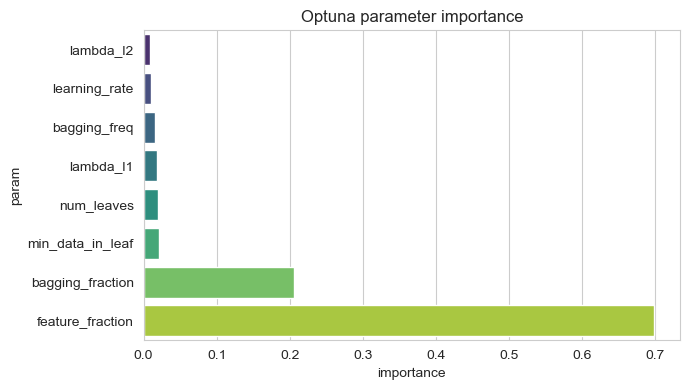

In [7]:
# Optuna parameter importance
try:
    imp_df = pd.DataFrame(
        optuna.importance.get_param_importances(study).items(),
        columns=['param', 'importance']).sort_values('importance', ascending=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(data=imp_df, y='param', x='importance', palette='viridis', ax=ax)
    ax.set_title('Optuna parameter importance')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f'param importance skipped: {e}')

## 4. Experiment 3 — Multi-seed blending

Same tuned config, three different random seeds. Average OOF and test predictions.

In [8]:
seeds = [42, 123, 2024]
seed_oofs, seed_test, seed_aucs = [], [], []

for s in seeds:
    params_s = {**tuned_params, 'seed': s, 'bagging_seed': s, 'feature_fraction_seed': s}
    t0 = time.time()
    aucs, oof, test_folds = cv_lgbm(params_s, X_train, y, X_test_arr=X_test)
    seed_oofs.append(oof)
    seed_test.append(test_folds.mean(axis=1))
    seed_aucs.append(aucs.mean())
    print(f'  seed={s:>4d}: CV={aucs.mean():.5f}  (time={time.time()-t0:.0f}s)')

ens_oof = np.mean(seed_oofs, axis=0)
ens_test = np.mean(seed_test, axis=0)
ens_auc = roc_auc_score(y, ens_oof)
print(f'\nSeed-averaged OOF AUC: {ens_auc:.5f}  '
      f'(individual mean: {np.mean(seed_aucs):.5f})')

  seed=  42: CV=0.91018  (time=721s)
  seed= 123: CV=0.90983  (time=668s)
  seed=2024: CV=0.90999  (time=800s)

Seed-averaged OOF AUC: 0.91069  (individual mean: 0.91000)


## 5. Summary

In [9]:
summary = pd.DataFrame([
    ('Baseline (notebook 05)', BASELINE_AUC, BASELINE_AUC - BASELINE_AUC),
    (f'Exp1: best feature_fraction sweep', best_ff_row.mean_auc, best_ff_row.mean_auc - BASELINE_AUC),
    ('Exp2: tuned (Optuna, 5-fold CV)', tuned_aucs.mean(), tuned_aucs.mean() - BASELINE_AUC),
    ('Exp3: tuned + 3-seed blend', ens_auc, ens_auc - BASELINE_AUC),
], columns=['experiment', 'auc', 'delta_vs_baseline'])
summary

,experiment,auc,delta_vs_baseline
0,Baseline (notebook 05),0.904771,0.000000
1,Exp1: best feature_fraction sweep,0.904795,0.000024
2,"Exp2: tuned (Optuna, 5-fold CV)",0.909894,0.005123
3,Exp3: tuned + 3-seed blend,0.910687,0.005916


## 6. Final submission

If the seed-blended ensemble beats baseline, it becomes the canonical LightGBM submission.

In [10]:
if ens_auc > BASELINE_AUC + 1e-5:
    submission = pd.DataFrame({'ID_code': test_ids, 'target': ens_test})
    submission.to_csv('submission_lightgbm_tuned.csv', index=False)
    np.savez(f'{ART_DIR}/lgbm_tuned_predictions.npz',
             oof=ens_oof, test_proba=ens_test, seed_aucs=np.array(seed_aucs),
             tuned_params=str(tuned_params))
    print(f'Wrote submission_lightgbm_tuned.csv (ensemble OOF = {ens_auc:.5f})')
    print(f'Wrote {ART_DIR}/lgbm_tuned_predictions.npz')
else:
    print(f'Tuned ensemble ({ens_auc:.5f}) did not beat baseline ({BASELINE_AUC:.5f}).')
    print('submission_lightgbm.csv from notebook 05 stays canonical.')

Wrote submission_lightgbm_tuned.csv (ensemble OOF = 0.91069)
Wrote artifacts/lgbm_tuned_predictions.npz
